In [ ]:

import pandas as pd
import os

# Path to the dataset already present in Colab
file_name = "/NF-CSE-CIC-IDS2018.parquet"

# Check whether the file exists
if not os.path.exists(file_name):
    file_name = "/content/NF-CSE-CIC-IDS2018.parquet"

print("Loading dataset:", file_name)

# Load Parquet dataset
df = pd.read_parquet(file_name)

# Display dataset details
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nLabel distribution:")
if "Label" in df.columns:
    print(df["Label"].value_counts(dropna=False))
elif "Attack" in df.columns:
    print(df["Attack"].value_counts(dropna=False))
else:
    print("Label column not found. Check the column names above.")


Loading dataset: /NF-CSE-CIC-IDS2018.parquet
Dataset shape: (5918803, 12)

Column names:
['L4_SRC_PORT', 'L4_DST_PORT', 'PROTOCOL', 'L7_PROTO', 'IN_BYTES', 'OUT_BYTES', 'IN_PKTS', 'OUT_PKTS', 'TCP_FLAGS', 'FLOW_DURATION_MILLISECONDS', 'Label', 'Attack']

First 5 rows:


,L4_SRC_PORT,L4_DST_PORT,PROTOCOL,L7_PROTO,IN_BYTES,OUT_BYTES,IN_PKTS,OUT_PKTS,TCP_FLAGS,FLOW_DURATION_MILLISECONDS,Label,Attack
0,51128,443,6,91.000000,152,0,3,0,194,4285680,0,Benign
1,443,51036,6,91.178001,994,979,7,7,24,4234714,0,Benign
2,12262,445,6,0.000000,585,344,5,4,30,4294106,0,Benign
3,61023,53,17,0.000000,136,168,2,2,0,4293985,0,Benign
4,443,51037,6,91.178001,72,40,1,1,24,4294845,0,Benign



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5918803 entries, 0 to 5918802
Data columns (total 12 columns):
 #   Column                      Dtype  
---  ------                      -----  
 0   L4_SRC_PORT                 int32  
 1   L4_DST_PORT                 int32  
 2   PROTOCOL                    int8   
 3   L7_PROTO                    float32
 4   IN_BYTES                    int32  
 5   OUT_BYTES                   int32  
 6   IN_PKTS                     int32  
 7   OUT_PKTS                    int32  
 8   TCP_FLAGS                   int16  
 9   FLOW_DURATION_MILLISECONDS  int32  
 10  Label                       int8   
 11  Attack                      object 
dtypes: float32(1), int16(1), int32(7), int8(2), object(1)
memory usage: 248.4+ MB

Label distribution:
Label
0    5534773
1     384030
Name: count, dtype: int64


In [ ]:
print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())

print("\nLabel distribution:")
for col in ["Label", "Attack"]:
    if col in df.columns:
        print(f"\n{col}:")
        print(df[col].value_counts(dropna=False))

Shape: (5918803, 12)

Columns: ['L4_SRC_PORT', 'L4_DST_PORT', 'PROTOCOL', 'L7_PROTO', 'IN_BYTES', 'OUT_BYTES', 'IN_PKTS', 'OUT_PKTS', 'TCP_FLAGS', 'FLOW_DURATION_MILLISECONDS', 'Label', 'Attack']

Label distribution:

Label:
Label
0    5534773
1     384030
Name: count, dtype: int64

Attack:
Attack
Benign                      5534773
DoS attacks-Hulk             108129
SSH-Bruteforce                71148
Infilteration                 59374
DDoS attacks-LOIC-HTTP        49751
DoS attacks-GoldenEye         32582
DoS attacks-Slowloris         17109
Bot                           15498
DoS attacks-SlowHTTPTest      14116
FTP-BruteForce                14116
DDOS attack-LOIC-UDP           1667
DDOS attack-HOIC                230
Brute Force -Web                173
Brute Force -XSS                101
SQL Injection                    36
Name: count, dtype: int64


In [ ]:
print("Missing values per column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nFeature data types:")
print(df.dtypes)

Missing values per column:
L4_SRC_PORT                   0
L4_DST_PORT                   0
PROTOCOL                      0
L7_PROTO                      0
IN_BYTES                      0
OUT_BYTES                     0
IN_PKTS                       0
OUT_PKTS                      0
TCP_FLAGS                     0
FLOW_DURATION_MILLISECONDS    0
Label                         0
Attack                        0
dtype: int64

Duplicate rows: 0

Feature data types:
L4_SRC_PORT                     int32
L4_DST_PORT                     int32
PROTOCOL                         int8
L7_PROTO                      float32
IN_BYTES                        int32
OUT_BYTES                       int32
IN_PKTS                         int32
OUT_PKTS                        int32
TCP_FLAGS                       int16
FLOW_DURATION_MILLISECONDS      int32
Label                            int8
Attack                         object
dtype: object


In [ ]:
# Features used by both models
feature_cols = [
    "PROTOCOL",
    "L7_PROTO",
    "IN_BYTES",
    "OUT_BYTES",
    "IN_PKTS",
    "OUT_PKTS",
    "TCP_FLAGS",
    "FLOW_DURATION_MILLISECONDS"
]

X = df[feature_cols].copy()

# Binary target: 0 = Benign, 1 = Attack
y_binary = df["Label"].astype(int)

# Multiclass target: benign + individual attack types
y_multi = df["Attack"].astype(str)

print("Feature matrix shape:", X.shape)
print("\nBinary target distribution:")
print(y_binary.value_counts())

print("\nMulticlass target distribution:")
print(y_multi.value_counts())

Feature matrix shape: (5918803, 8)

Binary target distribution:
Label
0    5534773
1     384030
Name: count, dtype: int64

Multiclass target distribution:
Attack
Benign                      5534773
DoS attacks-Hulk             108129
SSH-Bruteforce                71148
Infilteration                 59374
DDoS attacks-LOIC-HTTP        49751
DoS attacks-GoldenEye         32582
DoS attacks-Slowloris         17109
Bot                           15498
DoS attacks-SlowHTTPTest      14116
FTP-BruteForce                14116
DDOS attack-LOIC-UDP           1667
DDOS attack-HOIC                230
Brute Force -Web                173
Brute Force -XSS                101
SQL Injection                    36
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_binary_train, y_binary_test = train_test_split(
    X, y_binary,
    test_size=0.2,
    random_state=42,
    stratify=y_binary
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nBinary training distribution:")
print(y_binary_train.value_counts(normalize=True).round(4))

print("\nBinary testing distribution:")
print(y_binary_test.value_counts(normalize=True).round(4))

Training features: (4735042, 8)
Testing features: (1183761, 8)

Binary training distribution:
Label
0    0.9351
1    0.0649
Name: proportion, dtype: float64

Binary testing distribution:
Label
0    0.9351
1    0.0649
Name: proportion, dtype: float64


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils.class_weight import compute_sample_weight
import time

# Give more weight to the minority attack class
sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_binary_train
)

rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

start_time = time.time()

rf_model.fit(X_train, y_binary_train)

rf_train_time = time.time() - start_time

print(f"Random Forest training time: {rf_train_time:.2f} seconds")
print("Binary model training complete.")

NameError: name 'y_binary_train' is not defined

In [ ]:
print("y_binary_train exists:", "y_binary_train" in globals())
print("X_train exists:", "X_train" in globals())
print("y_train exists:", "y_train" in globals())

y_binary_train exists: False
X_train exists: False
y_train exists: False


In [ ]:
y_binary_train = y_train

NameError: name 'y_train' is not defined

In [ ]:
print("df exists:", "df" in globals())

if "df" in globals():
    print("Dataset shape:", df.shape)
    print("Columns:", df.columns.tolist())
else:
    print("Dataset is not loaded. Load it before continuing.")

df exists: False
Dataset is not loaded. Load it before continuing.


In [ ]:

import os
import pandas as pd

# Check common locations for your Parquet file
possible_paths = [
    "/content/NF-CSE-CIC-IDS2018.parquet",
    "/NF-CSE-CIC-IDS2018.parquet"
]

file_path = next(
    (p for p in possible_paths if os.path.exists(p)),
    None
)

if file_path is None:
    print("Dataset not found in the common locations.")
    print("Open the Files panel and right-click the dataset.")
    print("Select Copy path, then use that path below.")
else:
    print("Loading:", file_path)
    df = pd.read_parquet(file_path)

    print("Dataset shape:", df.shape)
    print("\nColumn names:")
    print(df.columns.tolist())

    print("\nFirst 5 rows:")
    display(df.head())

    print("\nDataset information:")
    df.info()


Dataset not found in the common locations.
Open the Files panel and right-click the dataset.
Select Copy path, then use that path below.


In [ ]:
import os

matches = []

for folder in ["/content", "/"]:
    for root, dirs, files in os.walk(folder):
        # Avoid scanning virtual system directories
        dirs[:] = [d for d in dirs if d not in {
            "proc", "sys", "dev", "usr", "lib",
            "lib64", "bin", "sbin"
        }]

        for filename in files:
            if filename.lower().endswith(".parquet") and "nf-cse-cic-ids2018" in filename.lower():
                path = os.path.join(root, filename)
                if path not in matches:
                    matches.append(path)

        if folder == "/content" and root == "/content":
            break

print("Dataset files found:")
for path in matches:
    print(path)

Dataset files found:


In [ ]:

import pandas as pd
import os

file_path = "/NGC-DL-CONTAINER-LICENSE"

# Load the Parquet dataset
df = pd.read_parquet(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nDataset information:")
df.info()


ArrowInvalid: Could not open Parquet input source '<Buffer>': Parquet magic bytes not found in footer. Either the file is corrupted or this is not a parquet file.

In [ ]:

import os

print("File path:", file_path)
print("File exists:", os.path.exists(file_path))

if os.path.exists(file_path):
    print("File size:", round(os.path.getsize(file_path) / (1024**3), 3), "GB")

    with open(file_path, "rb") as f:
        print("First 4 bytes:", f.read(4).hex())

    with open(file_path, "rb") as f:
        f.seek(max(0, os.path.getsize(file_path) - 8))
        print("Last 8 bytes:", f.read(8))


File path: /NGC-DL-CONTAINER-LICENSE
File exists: True
File size: 0.0 GB
First 4 bytes: 4e564944
Last 8 bytes: b', 2021)\n'


In [ ]:

import os

search_dirs = ["/content", "/tmp", "/mnt/data"]
found_files = []

for base in search_dirs:
    if os.path.exists(base):
        for root, dirs, files in os.walk(base):
            for name in files:
                if "NF-CSE-CIC-IDS2018" in name.upper():
                    path = os.path.join(root, name)
                    found_files.append(path)
                    print(
                        "Found:", path,
                        "| Size:",
                        round(os.path.getsize(path) / (1024**3), 3),
                        "GB"
                    )

if not found_files:
    print("Dataset not found in these locations.")


Dataset not found in these locations.


In [ ]:

import os
import pandas as pd

file_path = "/NF-CSE-CIC-IDS2018.parquet"

# Verify the file exists
print("File exists:", os.path.exists(file_path))

if os.path.exists(file_path):
    print("File size:", round(os.path.getsize(file_path) / (1024**3), 3), "GB")

    # Load the dataset
    df = pd.read_parquet(file_path)

    print("\nDataset loaded successfully!")
    print("Dataset shape:", df.shape)

    print("\nColumn names:")
    print(df.columns.tolist())

    print("\nFirst 5 rows:")
    display(df.head())

    print("\nDataset information:")
    df.info()
else:
    print("File not found. Check the path in the Colab Files panel.")


File exists: True
File size: 0.058 GB

Dataset loaded successfully!
Dataset shape: (5918803, 12)

Column names:
['L4_SRC_PORT', 'L4_DST_PORT', 'PROTOCOL', 'L7_PROTO', 'IN_BYTES', 'OUT_BYTES', 'IN_PKTS', 'OUT_PKTS', 'TCP_FLAGS', 'FLOW_DURATION_MILLISECONDS', 'Label', 'Attack']

First 5 rows:


,L4_SRC_PORT,L4_DST_PORT,PROTOCOL,L7_PROTO,IN_BYTES,OUT_BYTES,IN_PKTS,OUT_PKTS,TCP_FLAGS,FLOW_DURATION_MILLISECONDS,Label,Attack
0,51128,443,6,91.000000,152,0,3,0,194,4285680,0,Benign
1,443,51036,6,91.178001,994,979,7,7,24,4234714,0,Benign
2,12262,445,6,0.000000,585,344,5,4,30,4294106,0,Benign
3,61023,53,17,0.000000,136,168,2,2,0,4293985,0,Benign
4,443,51037,6,91.178001,72,40,1,1,24,4294845,0,Benign



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5918803 entries, 0 to 5918802
Data columns (total 12 columns):
 #   Column                      Dtype  
---  ------                      -----  
 0   L4_SRC_PORT                 int32  
 1   L4_DST_PORT                 int32  
 2   PROTOCOL                    int8   
 3   L7_PROTO                    float32
 4   IN_BYTES                    int32  
 5   OUT_BYTES                   int32  
 6   IN_PKTS                     int32  
 7   OUT_PKTS                    int32  
 8   TCP_FLAGS                   int16  
 9   FLOW_DURATION_MILLISECONDS  int32  
 10  Label                       int8   
 11  Attack                      object 
dtypes: float32(1), int16(1), int32(7), int8(2), object(1)
memory usage: 248.4+ MB


In [ ]:

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

# 1. Remove duplicate records
df = df.drop_duplicates().copy()

# 2. Replace infinite values and remove rows with missing values
df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.dropna(subset=["Label", "Attack"], inplace=True)

# 3. Take a reproducible stratified sample using the binary label
sample_size = min(500_000, len(df))

df_sample, _ = train_test_split(
    df,
    train_size=sample_size,
    stratify=df["Label"],
    random_state=42
)

df_sample = df_sample.reset_index(drop=True)

print("Sample shape:", df_sample.shape)
print("\nBinary label distribution:")
print(df_sample["Label"].value_counts(normalize=True))

print("\nAttack class distribution:")
print(df_sample["Attack"].value_counts())

# 4. Prepare binary and multi-class targets
y_binary = df_sample["Label"].astype(int)
y_multi = df_sample["Attack"].astype(str)

# 5. Keep numeric features, excluding labels and port identifiers
drop_cols = [
    "Label", "Attack",
    "L4_SRC_PORT", "L4_DST_PORT"
]

X = df_sample.drop(columns=drop_cols, errors="ignore")
X = X.select_dtypes(include=[np.number]).copy()

# Clean remaining invalid values
X.replace([np.inf, -np.inf], np.nan, inplace=True)
X = X.fillna(X.median())

# 6. Create stratified train/test splits for binary classification
X_train, X_test, y_binary_train, y_binary_test = train_test_split(
    X,
    y_binary,
    test_size=0.20,
    stratify=y_binary,
    random_state=42
)

# 7. Create stratified train/test splits for multi-class classification
X_multi_train, X_multi_test, y_multi_train, y_multi_test = train_test_split(
    X,
    y_multi,
    test_size=0.20,
    stratify=y_multi,
    random_state=42
)

print("\nPreprocessing complete!")
print("Feature count:", X.shape[1])
print("Binary training set:", X_train.shape)
print("Binary test set:", X_test.shape)
print("Multi-class training set:", X_multi_train.shape)
print("Multi-class test set:", X_multi_test.shape)
print("\nBinary training labels:")
print(y_binary_train.value_counts())
print("\nMulti-class training labels:")
print(y_multi_train.value_counts())


Sample shape: (500000, 12)

Binary label distribution:
Label
0    0.935116
1    0.064884
Name: proportion, dtype: float64

Attack class distribution:
Attack
Benign                      467558
DoS attacks-Hulk              8939
SSH-Bruteforce                6107
Infilteration                 5073
DDoS attacks-LOIC-HTTP        4202
DoS attacks-GoldenEye         2843
DoS attacks-Slowloris         1481
Bot                           1219
FTP-BruteForce                1204
DoS attacks-SlowHTTPTest      1174
DDOS attack-LOIC-UDP           148
DDOS attack-HOIC                22
Brute Force -Web                18
Brute Force -XSS                 9
SQL Injection                    3
Name: count, dtype: int64

Preprocessing complete!
Feature count: 8
Binary training set: (400000, 8)
Binary test set: (100000, 8)
Multi-class training set: (400000, 8)
Multi-class test set: (100000, 8)

Binary training labels:
Label
0    374046
1     25954
Name: count, dtype: int64

Multi-class training labels:
Attac

Random Forest training time: 37.89 seconds

Evaluation metrics:


,Model,Task,Accuracy,Precision_macro,Recall_macro,F1_macro,F1_weighted,Training_time_s,Inference_time_per_sample_ms
0,Random Forest,Binary,0.98,0.9136,0.9237,0.9186,0.9801,37.8933,0.0156



Classification report:
              precision    recall  f1-score   support

      Benign       0.99      0.99      0.99     93512
      Attack       0.84      0.86      0.85      6488

    accuracy                           0.98    100000
   macro avg       0.91      0.92      0.92    100000
weighted avg       0.98      0.98      0.98    100000



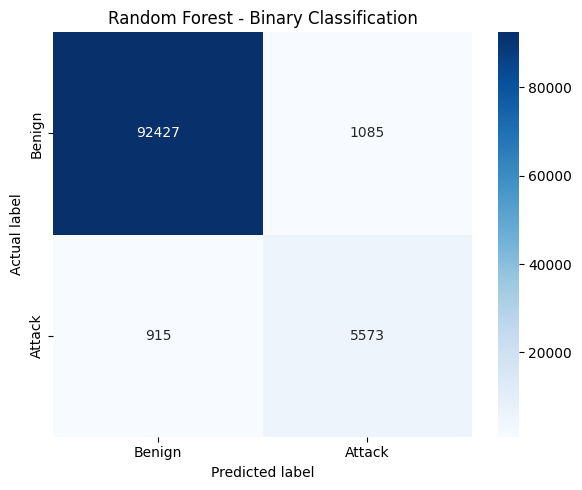

In [ ]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Train Random Forest for benign vs attack classification
rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

start_time = time.time()
rf_model.fit(X_train, y_binary_train)
rf_train_time = time.time() - start_time

print(f"Random Forest training time: {rf_train_time:.2f} seconds")

# Predict on the test set
start_time = time.time()
rf_binary_pred = rf_model.predict(X_test)
rf_inference_time = (time.time() - start_time) / len(X_test)

# Calculate evaluation metrics
rf_binary_results = {
    "Model": "Random Forest",
    "Task": "Binary",
    "Accuracy": accuracy_score(y_binary_test, rf_binary_pred),
    "Precision_macro": precision_score(
        y_binary_test, rf_binary_pred, average="macro", zero_division=0
    ),
    "Recall_macro": recall_score(
        y_binary_test, rf_binary_pred, average="macro", zero_division=0
    ),
    "F1_macro": f1_score(
        y_binary_test, rf_binary_pred, average="macro", zero_division=0
    ),
    "F1_weighted": f1_score(
        y_binary_test, rf_binary_pred, average="weighted", zero_division=0
    ),
    "Training_time_s": rf_train_time,
    "Inference_time_per_sample_ms": rf_inference_time * 1000
}

print("\nEvaluation metrics:")
display(pd.DataFrame([rf_binary_results]).round(4))

print("\nClassification report:")
print(classification_report(
    y_binary_test,
    rf_binary_pred,
    target_names=["Benign", "Attack"],
    zero_division=0
))

# Plot confusion matrix
cm = confusion_matrix(y_binary_test, rf_binary_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Benign", "Attack"],
    yticklabels=["Benign", "Attack"]
)
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title("Random Forest - Binary Classification")
plt.tight_layout()
plt.savefig("rf_binary_confusion_matrix.png", dpi=300)
plt.show()


In [ ]:
print("Dataset loaded:", "df" in globals())
print("Sample available:", "df_sample" in globals())
print("Features available:", "X" in globals())
print("Binary labels available:", "y_binary" in globals())
print("Attack labels available:", "y_multi" in globals())

Dataset loaded: False
Sample available: False
Features available: False
Binary labels available: False
Attack labels available: False


In [ ]:
import os

print("Files in /content:")
print(os.listdir("/content"))

print("\nIs dataset in root directory?")
print(os.path.exists("/NF-CSE-CIC-IDS2018.parquet"))

print("\nIs dataset in /content?")
print(os.path.exists("/content/NF-CSE-CIC-IDS2018.parquet"))

Files in /content:
['.config', 'sample_data']

Is dataset in root directory?
True

Is dataset in /content?
False


In [ ]:
import pandas as pd

df = pd.read_parquet("/NF-CSE-CIC-IDS2018.parquet")

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

df.head()

Dataset loaded successfully!
Shape: (5918803, 12)

Columns:
['L4_SRC_PORT', 'L4_DST_PORT', 'PROTOCOL', 'L7_PROTO', 'IN_BYTES', 'OUT_BYTES', 'IN_PKTS', 'OUT_PKTS', 'TCP_FLAGS', 'FLOW_DURATION_MILLISECONDS', 'Label', 'Attack']


,L4_SRC_PORT,L4_DST_PORT,PROTOCOL,L7_PROTO,IN_BYTES,OUT_BYTES,IN_PKTS,OUT_PKTS,TCP_FLAGS,FLOW_DURATION_MILLISECONDS,Label,Attack
0,51128,443,6,91.000000,152,0,3,0,194,4285680,0,Benign
1,443,51036,6,91.178001,994,979,7,7,24,4234714,0,Benign
2,12262,445,6,0.000000,585,344,5,4,30,4294106,0,Benign
3,61023,53,17,0.000000,136,168,2,2,0,4293985,0,Benign
4,443,51037,6,91.178001,72,40,1,1,24,4294845,0,Benign


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Remove duplicate rows
df = df.drop_duplicates()

# Remove rows where either target label is missing
df = df.dropna(subset=["Label", "Attack"])

# Convert binary target to integer
df["Label"] = df["Label"].astype(int)

# Create a stratified sample of up to 500,000 rows
sample_size = min(500_000, len(df))

df_sample = (
    df.groupby("Label", group_keys=False)
      .apply(
          lambda group: group.sample(
              n=round(sample_size * len(group) / len(df)),
              random_state=42
          )
      )
)

# Keep the sample at no more than 500,000 rows
if len(df_sample) > sample_size:
    df_sample = df_sample.sample(n=sample_size, random_state=42)

print("Original dataset after cleaning:", df.shape)
print("Sample shape:", df_sample.shape)
print("\nBinary label distribution:")
print(df_sample["Label"].value_counts())
print("\nAttack category distribution:")
print(df_sample["Attack"].value_counts())

Original dataset after cleaning: (5918803, 12)
Sample shape: (500000, 12)

Binary label distribution:
Label
0    467558
1     32442
Name: count, dtype: int64

Attack category distribution:
Attack
Benign                      467558
DoS attacks-Hulk              9126
SSH-Bruteforce                6101
Infilteration                 5137
DDoS attacks-LOIC-HTTP        4129
DoS attacks-GoldenEye         2753
DoS attacks-Slowloris         1408
Bot                           1240
FTP-BruteForce                1178
DoS attacks-SlowHTTPTest      1153
DDOS attack-LOIC-UDP           158
DDOS attack-HOIC                26
Brute Force -Web                17
Brute Force -XSS                12
SQL Injection                    4
Name: count, dtype: int64


/tmp/ipykernel_2725/487736531.py:18: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


In [ ]:
# Separate features and target labels

# Remove target columns and port identifiers from the input features
drop_columns = ["Label", "Attack", "L4_SRC_PORT", "L4_DST_PORT"]

X = df_sample.drop(columns=drop_columns)

# Binary target: 0 = Benign, 1 = Attack
y_binary = df_sample["Label"]

# Multiclass target: predict the specific attack category
y_multi = df_sample["Attack"]

# Keep numeric features only
X = X.select_dtypes(include=["number"])

# Handle any remaining missing or infinite feature values
import numpy as np

X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median())

print("Features shape:", X.shape)
print("Binary labels shape:", y_binary.shape)
print("Multiclass labels shape:", y_multi.shape)

print("\nFeatures used:")
print(X.columns.tolist())

print("\nBinary target distribution:")
print(y_binary.value_counts())

print("\nNumber of attack categories:", y_multi.nunique())

Features shape: (500000, 8)
Binary labels shape: (500000,)
Multiclass labels shape: (500000,)

Features used:
['PROTOCOL', 'L7_PROTO', 'IN_BYTES', 'OUT_BYTES', 'IN_PKTS', 'OUT_PKTS', 'TCP_FLAGS', 'FLOW_DURATION_MILLISECONDS']

Binary target distribution:
Label
0    467558
1     32442
Name: count, dtype: int64

Number of attack categories: 15


In [ ]:
print("X_multi_train exists:", "X_multi_train" in globals())
print("X_multi_test exists:", "X_multi_test" in globals())
print("y_multi_train exists:", "y_multi_train" in globals())
print("y_multi_test exists:", "y_multi_test" in globals())
print("rf_multi exists:", "rf_multi" in globals())

X_multi_train exists: False
X_multi_test exists: False
y_multi_train exists: False
y_multi_test exists: False
rf_multi exists: False


In [ ]:
from sklearn.model_selection import train_test_split

X_multi_train, X_multi_test, y_multi_train, y_multi_test = train_test_split(
    X,
    y_multi,
    test_size=0.20,
    random_state=42,
    stratify=y_multi
)

print("Multiclass split created successfully!")
print("Training features:", X_multi_train.shape)
print("Testing features:", X_multi_test.shape)
print("Training labels:", y_multi_train.shape)
print("Testing labels:", y_multi_test.shape)

Multiclass split created successfully!
Training features: (400000, 8)
Testing features: (100000, 8)
Training labels: (400000,)
Testing labels: (100000,)


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import time

# Initialize the Random Forest multiclass model
rf_multi = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train the model
start_time = time.time()

rf_multi.fit(X_multi_train, y_multi_train)

rf_multi_train_time = time.time() - start_time

print("Random Forest multiclass training completed!")
print(f"Training time: {rf_multi_train_time:.2f} seconds")

Random Forest multiclass training completed!
Training time: 43.42 seconds


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)
import time

# Predict attack categories on unseen test data
start_time = time.time()
y_multi_pred = rf_multi.predict(X_multi_test)
rf_multi_inference_time = time.time() - start_time

# Calculate evaluation metrics
rf_multi_accuracy = accuracy_score(y_multi_test, y_multi_pred)
rf_multi_macro_f1 = f1_score(
    y_multi_test, y_multi_pred, average="macro", zero_division=0
)
rf_multi_weighted_f1 = f1_score(
    y_multi_test, y_multi_pred, average="weighted", zero_division=0
)

print("=== Random Forest Multiclass Results ===")
print(f"Accuracy: {rf_multi_accuracy:.4f}")
print(f"Macro F1-score: {rf_multi_macro_f1:.4f}")
print(f"Weighted F1-score: {rf_multi_weighted_f1:.4f}")
print(f"Inference time: {rf_multi_inference_time:.2f} seconds")
print(f"Average inference time per sample: "
      f"{rf_multi_inference_time / len(X_multi_test) * 1000:.4f} ms")

print("\n=== Classification Report ===")
print(classification_report(
    y_multi_test,
    y_multi_pred,
    zero_division=0
))

print("\n=== Confusion Matrix ===")
print(confusion_matrix(y_multi_test, y_multi_pred))

=== Random Forest Multiclass Results ===
Accuracy: 0.8597
Macro F1-score: 0.6270
Weighted F1-score: 0.9116
Inference time: 3.75 seconds
Average inference time per sample: 0.0375 ms

=== Classification Report ===
                          precision    recall  f1-score   support

                  Benign       0.99      0.86      0.92     93512
                     Bot       1.00      1.00      1.00       248
        Brute Force -Web       1.00      0.33      0.50         3
        Brute Force -XSS       0.00      0.00      0.00         2
        DDOS attack-HOIC       0.60      0.60      0.60         5
    DDOS attack-LOIC-UDP       0.85      0.90      0.88        31
  DDoS attacks-LOIC-HTTP       0.70      0.99      0.82       826
   DoS attacks-GoldenEye       0.99      0.99      0.99       551
        DoS attacks-Hulk       1.00      0.99      0.99      1825
DoS attacks-SlowHTTPTest       0.49      1.00      0.66       231
   DoS attacks-Slowloris       0.99      0.99      0.99      